# Portifolio_2Bimestre_2 — Segmentação

Comparação entre segmentação semântica e por instância em skimage.data.coins e em uma segunda imagem de skimage.data.

In [1]:
import inspect
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import data, feature, filters, morphology, segmentation, util
from IPython.display import display

PASTA_SAIDA = Path("plots_segmentacao")
PASTA_SAIDA.mkdir(exist_ok=True)

def segmentar_por_instancia(
    imagem,
    ajuste_limiar=0,
    raio_fechamento=0,
    area_minima=0,
    distancia_minima=10,
    remover_componentes_na_borda=False,
):
    imagem_u8 = util.img_as_ubyte(imagem)
    suavizada = filters.gaussian(imagem_u8, sigma=1, preserve_range=True)
    limiar = filters.threshold_otsu(suavizada) + ajuste_limiar
    mascara = suavizada > limiar

    if raio_fechamento > 0:
        mascara = morphology.closing(mascara, footprint=morphology.disk(raio_fechamento))
    mascara = ndi.binary_fill_holes(mascara)

    if area_minima > 0:
        parametros = inspect.signature(morphology.remove_small_objects).parameters
        if "max_size" in parametros:
            mascara = morphology.remove_small_objects(mascara, max_size=area_minima - 1)
        else:
            mascara = morphology.remove_small_objects(mascara, min_size=area_minima)

    if remover_componentes_na_borda:
        mascara = segmentation.clear_border(mascara)

    distancia = ndi.distance_transform_edt(mascara)
    coordenadas = feature.peak_local_max(
        distancia,
        min_distance=distancia_minima,
        labels=mascara,
        exclude_border=False,
    )
    marcadores = np.zeros(mascara.shape, dtype=np.int32)
    if len(coordenadas):
        marcadores[tuple(coordenadas.T)] = np.arange(1, len(coordenadas) + 1)

    rotulos = segmentation.watershed(-distancia, marcadores, mask=mascara)
    return imagem_u8, limiar, mascara, rotulos


def plotar_comparacao(imagem, mascara, rotulos, nome_objeto, arquivo):
    quantidade = int(rotulos.max())
    paleta = plt.get_cmap("hsv")(np.linspace(0, 1, quantidade + 1))[:, :3]
    paleta[0] = (0, 0, 0)
    imagem_instancias = paleta[rotulos]

    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8))
    eixos[0].imshow(imagem, cmap="gray")
    eixos[1].imshow(mascara, cmap="gray", vmin=0, vmax=1)
    eixos[2].imshow(imagem_instancias)
    titulos = (
        "Entrada",
        f"Semântica (1 classe: {nome_objeto})",
        f"Instância (1 cor por {nome_objeto})",
    )
    for eixo, titulo in zip(eixos, titulos):
        eixo.set_title(titulo, fontsize=13)
        eixo.axis("off")

    fig.tight_layout()
    fig.savefig(arquivo, dpi=200, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)


## 1. Moedas — skimage.data.coins

Instâncias encontradas: 24


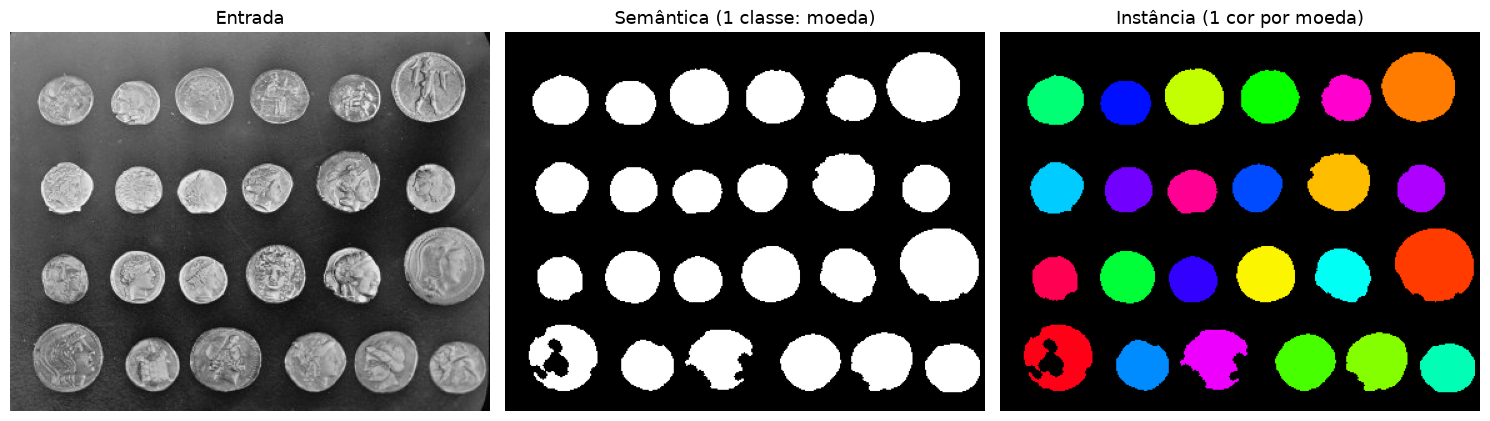

In [2]:
imagem_moedas = data.coins()
moedas, limiar_moedas, mascara_moedas, rotulos_moedas = segmentar_por_instancia(
    imagem_moedas,
    ajuste_limiar=25,
    raio_fechamento=3,
    area_minima=300,
    distancia_minima=29,
    remover_componentes_na_borda=True,
)
print(f"Instâncias encontradas: {rotulos_moedas.max()}")
plotar_comparacao(
    moedas,
    mascara_moedas,
    rotulos_moedas,
    "moeda",
    PASTA_SAIDA / "comparacao_coins.png",
)

## 2. Outra amostra — skimage.data.binary_blobs

Instâncias encontradas: 30


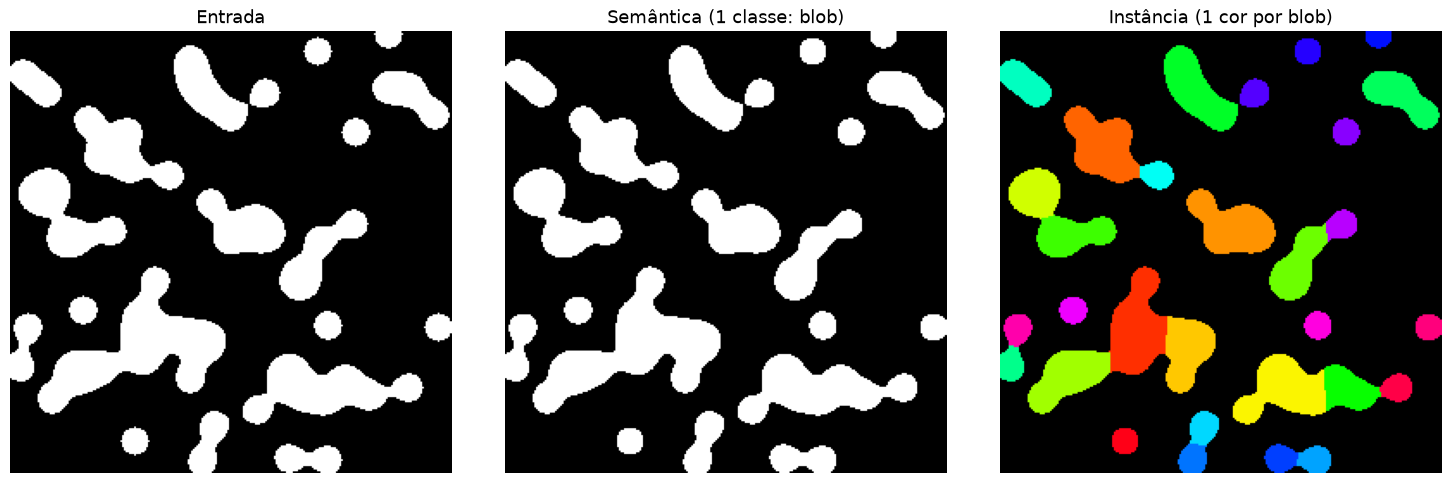

In [3]:
semente = (
    {"rng": 42}
    if "rng" in inspect.signature(data.binary_blobs).parameters
    else {"seed": 42}
)
imagem_blobs = data.binary_blobs(
    length=256,
    blob_size_fraction=0.12,
    volume_fraction=0.25,
    **semente,
)

blobs, limiar_blobs, mascara_blobs, rotulos_blobs = segmentar_por_instancia(
    imagem_blobs,
    area_minima=30,
    distancia_minima=18,
)
print(f"Instâncias encontradas: {rotulos_blobs.max()}")
plotar_comparacao(
    blobs,
    mascara_blobs,
    rotulos_blobs,
    "blob",
    PASTA_SAIDA / "comparacao_binary_blobs.png",
)

## Análise

Foram encontrados 24 rótulos nas moedas e 30 em binary_blobs. Nas moedas, a textura interfere no limiar; os blobs têm contraste mais limpo, mas algumas formas irregulares ou encostadas acabam divididas pelo watershed. A máscara semântica mantém uma classe para o primeiro plano; a segmentação por instância colore cada região separadamente.